<a href="https://colab.research.google.com/github/AnushGoel/cpu-diffusion-toolkit/blob/main/cpu_diffusion_toolkit.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Three Hugging Face Models on a CPU Budget

Text-to-image, image-to-video, and text classification, using only non-gated models, timed on a free Colab runtime and served through one Gradio app.

| Task | Model | Why this one |
|---|---|---|
| Text to Image | `stabilityai/sd-turbo` | 865M UNet, usable image in **one** denoising step |
| Image to Video | `ByteDance/AnimateDiff-Lightning` on SD 1.5 | Motion adapter distilled to 4 steps instead of ~25 with CFG |
| Text Classification | `SamLowe/roberta-base-go_emotions` | 28-label multi-label, 125M, sub-second on CPU |

The constraint shaped every choice. SDXL-Turbo needs ~10 GB for its UNet in fp32 and OOMs a free runtime; LTX-Video pairs a 2B transformer with a 4.7B text encoder; Stable Video Diffusion is gated and fails the brief outright. Cell 2 verifies the gating claim against the Hub rather than asking you to trust it.

**To run:** `Runtime → Change runtime type → CPU` (or T4 GPU, auto-detected), then `Runtime → Run all`. Not TPU: PyTorch cannot reach one without `torch_xla`, so it silently runs on the host CPU while spending your quota.

## 1. Configuration

One preset object drives every size and step count in the notebook, so there is a single place to trade quality against time.

In [1]:
PRESET = "report"      # "draft" = fast sanity check, "report" = what you submit

# Thread env vars have to be set before torch is imported or they are ignored.
import os
NCPU = os.cpu_count() or 2
os.environ.update(OMP_NUM_THREADS=str(NCPU), MKL_NUM_THREADS=str(NCPU))

from dataclasses import dataclass, asdict

@dataclass(frozen=True)
class Preset:
    label: str
    img_px: int          # text-to-image resolution
    img_steps: int
    vid_px: int          # video resolution; below 448 SD 1.5 degrades badly
    vid_frames: int
    vid_steps: int
    vid_strength: float  # effective steps = vid_steps * vid_strength

PRESETS = {
    "draft":  Preset("draft",  384, 1, 384, 6, 4, 0.75),
    "report": Preset("report", 512, 1, 512, 8, 4, 0.75),
}
CFG = PRESETS[PRESET]

MODELS = {
    "txt2img":  "stabilityai/sd-turbo",
    "base":     "stable-diffusion-v1-5/stable-diffusion-v1-5",
    "motion":   "ByteDance/AnimateDiff-Lightning",
    "tiny_vae": "madebyollin/taesd",
    "emotion":  "SamLowe/roberta-base-go_emotions",
}
MOTION_CKPT = "animatediff_lightning_4step_diffusers.safetensors"

print(f"preset={CFG.label}  cpus={NCPU}")
print(asdict(CFG))

preset=report  cpus=24
{'label': 'report', 'img_px': 512, 'img_steps': 1, 'vid_px': 512, 'vid_frames': 8, 'vid_steps': 4, 'vid_strength': 0.75}


In [2]:
!pip install -q --upgrade diffusers transformers accelerate safetensors huggingface_hub
!pip install -q --upgrade gradio imageio imageio-ffmpeg tabulate
print("ok")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.1/6.1 MB 76.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 24.2 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.8/40.8 kB 3.9 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.2/42.2 kB 3.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.4/31.4 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.5/64.5 kB 6.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 29.5/29.5 MB 38.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 86.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 147.1/147.1 kB 16.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.4/130.4 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 54.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 60.3/60.3 kB 6.3 MB/s eta 0:00:00
ok


## 2. Runtime

Three decisions get made here, each measured rather than assumed.

**Precision.** fp16 has no fast CPU convolution kernels, so on most CPUs fp32 wins. Newer server chips (Sapphire Rapids and later) have hardware bfloat16 via AMX, where bf16 is several times faster. A one-second conv benchmark picks the winner instead of hard-coding one.

**Attention slicing.** Trades speed for peak memory. Only worth enabling when RAM is tight, so it is gated on available RAM.

**Memory layout.** `channels_last` routes convolutions through MKLDNN's NHWC path, which is reliably faster on CPU.

In [3]:
import gc, time, json, platform, shutil, psutil, torch
from pathlib import Path
from contextlib import contextmanager

torch.set_num_threads(NCPU)
torch.set_grad_enabled(False)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
RAM_GB = psutil.virtual_memory().total / 1e9
TIGHT_RAM = RAM_GB < 16            # drives the attention-slicing decision

def _bench_conv(dtype, iters=8):
    x = torch.randn(1, 320, 64, 64, dtype=dtype)
    conv = torch.nn.Conv2d(320, 320, 3, padding=1).to(dtype)
    conv(x)                                            # warm up
    t0 = time.perf_counter()
    for _ in range(iters):
        conv(x)
    return (time.perf_counter() - t0) / iters

def pick_dtype():
    if DEVICE == "cuda":
        return torch.float16, "fp16 (GPU tensor cores)"
    fp32 = _bench_conv(torch.float32)
    try:
        bf16 = _bench_conv(torch.bfloat16)
    except Exception:
        return torch.float32, "fp32 (bf16 unsupported)"
    if bf16 < fp32 * 0.8:                              # needs a real margin to be worth it
        return torch.bfloat16, f"bf16 ({fp32 / bf16:.1f}x faster than fp32 here)"
    return torch.float32, f"fp32 (bf16 only {fp32 / bf16:.2f}x, not worth it)"

DTYPE, DTYPE_WHY = pick_dtype()
HOST = (torch.cuda.get_device_name(0) if DEVICE == "cuda"
        else f"CPU x{NCPU} threads, {RAM_GB:.0f} GB RAM")

print(f"device    {DEVICE}")
print(f"host      {HOST}")
print(f"precision {DTYPE_WHY}")
print(f"slicing   {'on (tight RAM)' if TIGHT_RAM else 'off (RAM is plentiful, favour speed)'}")
print(f"torch     {torch.__version__} / python {platform.python_version()}")

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


device    cpu
host      CPU x24 threads, 51 GB RAM
precision fp32 (bf16 only 0.00x, not worth it)
slicing   off (RAM is plentiful, favour speed)
torch     2.14.1+cpu / python 3.13.16


### Bench, artifacts, pipeline cache

Three small objects the whole notebook runs through. Timings become structured rows rather than a flat dict, so the summary table carries the settings that produced each number. Artifacts are registered centrally, so Task 2 can pull Task 1's output by name and the Gradio app and the report generator read the same manifest. The pipeline cache holds one diffusion model at a time and evicts least-recently-used, which keeps peak memory at one pipeline no matter how the cells are run.

In [4]:
OUT = Path("outputs"); OUT.mkdir(exist_ok=True)

class Bench:
    """Structured timing log: every row carries its own context."""
    def __init__(self):
        self.rows = []

    @contextmanager
    def track(self, task, phase, **meta):
        if DEVICE == "cuda":
            torch.cuda.synchronize()
        t0 = time.perf_counter()
        yield
        if DEVICE == "cuda":
            torch.cuda.synchronize()       # GPU work is async; otherwise you time the launch
        dt = time.perf_counter() - t0
        self.rows.append(dict(task=task, phase=phase, seconds=round(dt, 3), **meta))
        print(f"  {task} · {phase}: {dt:.2f}s")

    def frame(self):
        import pandas as pd
        return pd.DataFrame(self.rows)

    def total(self, task=None):
        return sum(r["seconds"] for r in self.rows if task is None or r["task"] == task)


class Artifacts(dict):
    """Named outputs on disk. One registry shared by the tasks, Gradio and the report."""
    def put(self, name, path):
        self[name] = str(path)
        return str(path)

    def save_manifest(self):
        (OUT / "manifest.json").write_text(json.dumps(self, indent=2))


class PipelineCache:
    """Holds at most `keep` heavy pipelines, evicting least-recently-used.

    Light models (the 125M classifier) are exempt from the cap and stay resident.
    """
    def __init__(self, keep=1):
        self.keep, self._store, self._order, self._heavy = keep, {}, [], set()

    def get(self, key, build, heavy=True):
        if key in self._store:
            self._order.remove(key); self._order.append(key)
            return self._store[key]
        if heavy:
            resident = [k for k in self._order if k in self._heavy]
            while len(resident) >= self.keep:
                self.evict(resident.pop(0))          # oldest HEAVY key, never a light one
        obj = build()
        self._store[key] = obj; self._order.append(key)
        if heavy:
            self._heavy.add(key)
        return obj

    def evict(self, key):
        self._store.pop(key, None)
        if key in self._order:
            self._order.remove(key)
        self._heavy.discard(key)
        gc.collect()
        if DEVICE == "cuda":
            torch.cuda.empty_cache()

    def clear(self):
        for k in list(self._order):
            self.evict(k)

bench, art, pipes = Bench(), Artifacts(), PipelineCache(keep=1)

def ram():
    v = psutil.virtual_memory()
    return f"RAM {v.used / 1e9:.1f}/{v.total / 1e9:.0f} GB"

def disk():
    u = shutil.disk_usage(".")
    return f"disk {u.used / 1e9:.0f}/{u.total / 1e9:.0f} GB"

print(ram(), "|", disk())

RAM 3.9/51 GB | disk 20/242 GB


## 3. Model audit

The brief asks for **free access (not gated)** models. Rather than assert it, query the Hub: `gated` is `False` for an open repo and `"auto"` or `"manual"` for one behind an access request. This table is the evidence.

In [5]:
import pandas as pd
from huggingface_hub import model_info

def audit(repo):
    i = model_info(repo)
    card = i.cardData or {}
    return dict(
        repo=repo,
        gated=i.gated if i.gated else False,
        license=card.get("license", "see card"),
        task=i.pipeline_tag or "-",
        downloads=f"{(i.downloads or 0):,}",
        likes=i.likes or 0,
    )

audit_df = pd.DataFrame([audit(r) for r in MODELS.values()])
audit_df.to_csv(OUT / "model_audit.csv", index=False)
art.put("model_audit", OUT / "model_audit.csv")

assert not any(audit_df["gated"]), "a selected model is gated"
print("All selected models are open access.\n")
audit_df

All selected models are open access.



,repo,gated,license,task,downloads,likes
0,stabilityai/sd-turbo,False,see card,text-to-image,"752,313",470
1,stable-diffusion-v1-5/stable-diffusion-v1-5,False,creativeml-openrail-m,text-to-image,"1,217,371",1330
2,ByteDance/AnimateDiff-Lightning,False,creativeml-openrail-m,text-to-video,"29,182",1014
3,madebyollin/taesd,False,mit,-,"17,646",73
4,SamLowe/roberta-base-go_emotions,False,mit,text-classification,"4,672,252",710


## 4. Shared loader

Every pipeline is built through one function, so the optimisations apply uniformly and are stated once.

- `variant="fp16"` halves the **download** even when we run in fp32, since weights are upcast on load.
- Passing `vae=` at construction stops diffusers fetching the original VAE at all.
- `channels_last` + conditional slicing, as decided in section 2.

In [6]:
from diffusers import AutoencoderTiny

def tiny_vae():
    return AutoencoderTiny.from_pretrained(MODELS["tiny_vae"], torch_dtype=DTYPE)

def build(cls, repo, **kw):
    try:
        pipe = cls.from_pretrained(repo, torch_dtype=DTYPE, variant="fp16", **kw)
    except Exception:
        pipe = cls.from_pretrained(repo, torch_dtype=DTYPE, **kw)   # no fp16 variant published
    pipe = pipe.to(DEVICE)
    pipe.unet.to(memory_format=torch.channels_last)                 # MKLDNN NHWC path
    if TIGHT_RAM:
        pipe.enable_attention_slicing()
    pipe.set_progress_bar_config(leave=False)
    return pipe

print("loader ready")

loader ready


---
## Task 1 — Text to Image: `stabilityai/sd-turbo`

Stable Diffusion 2.1 distilled with Adversarial Diffusion Distillation: an adversarial loss against a discriminator plus score distillation against the frozen teacher. The student learns to jump most of the denoising trajectory in one move, so a single network evaluation gives a usable image.

865M UNet, OpenCLIP ViT-H text encoder, SD 2.1 VAE (replaced here by TAESD). Roughly a third of SDXL-Turbo, which is why it fits.

`guidance_scale` must be `0.0` and `negative_prompt` is ignored, both because the model was distilled without classifier-free guidance. That also means one UNet pass per step rather than two.

In [7]:
from diffusers import AutoPipelineForText2Image
from diffusers.utils import make_image_grid

def load_txt2img():
    return build(AutoPipelineForText2Image, MODELS["txt2img"],
                 vae=tiny_vae(), safety_checker=None, requires_safety_checker=False)

with bench.track("Task 1", "load", model=MODELS["txt2img"]):
    txt2img = pipes.get("txt2img", load_txt2img)

print(ram(), "|", disk())

/usr/local/lib/python3.13/dist-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


config.json:   0%|          | 0.00/597 [00:00<?, ?B/s]

diffusion_pytorch_model.safetensors: reconstructing file:   0%|          |  0.00B / 9.79MB            

diffusion_pytorch_model.safetensors: downloading bytes:           |  0.00B            

model_index.json:   0%|          | 0.00/616 [00:00<?, ?B/s]

...

Fetching 10 files:   0%|          | 0/10 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/372 [00:00<?, ?it/s]

Expected types for vae: (<class 'diffusers.models.autoencoders.autoencoder_kl.AutoencoderKL'>,), got <class 'diffusers.models.autoencoders.autoencoder_tiny.AutoencoderTiny'>.


  Task 1 · load: 29.19s
RAM 9.4/51 GB | disk 23/242 GB


  0%|          | 0/1 [00:00<?, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

  Task 1 · generate:fox: 21.00s


  0%|          | 0/1 [00:00<?, ?it/s]

  Task 1 · generate:lighthouse: 17.00s


  0%|          | 0/1 [00:00<?, ?it/s]

  Task 1 · generate:cafe: 22.21s

mean 29.8s per 512px image on CPU x24 threads, 51 GB RAM


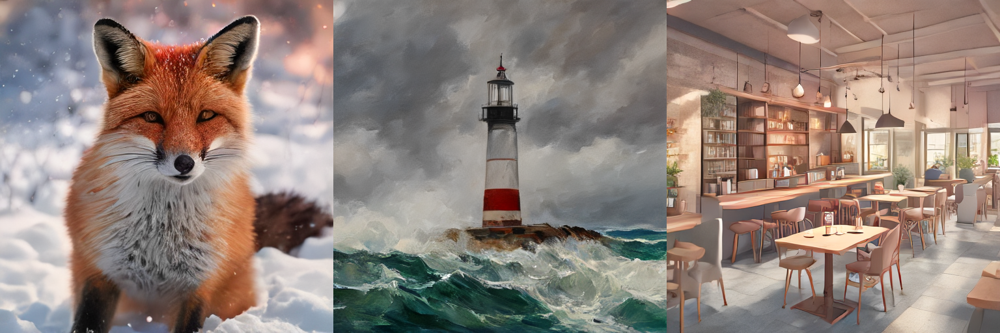

In [8]:
PROMPTS = {
    "fox":       "a cinematic photograph of a red fox sitting in deep snow at sunrise",
    "lighthouse":"an oil painting of a lighthouse in a storm, thick visible brush strokes",
    "cafe":      "an isometric 3D render of a cosy coffee shop, pastel colours, soft lighting",
}

def generate(prompt, px=None, steps=None, seed=42):
    px, steps = px or CFG.img_px, steps or CFG.img_steps
    return txt2img(prompt=prompt, num_inference_steps=steps, guidance_scale=0.0,
                   height=px, width=px,
                   generator=torch.Generator("cpu").manual_seed(seed)).images[0]

generate("warm up", px=CFG.img_px)      # first call picks conv algorithms; never time it

gallery = {}
for name, prompt in PROMPTS.items():
    with bench.track("Task 1", f"generate:{name}", px=CFG.img_px, steps=CFG.img_steps):
        gallery[name] = generate(prompt)
    art.put(f"t1_{name}", OUT / f"t1_{name}.png")
    gallery[name].save(art[f"t1_{name}"])

print(f"\nmean {bench.total('Task 1') / len(PROMPTS):.1f}s per {CFG.img_px}px image on {HOST}")
make_image_grid(list(gallery.values()), rows=1, cols=len(gallery))

**Step scaling.** CPU runtime is close to linear in step count, which is the entire reason a distilled model was chosen. This is the figure that justifies the model selection.

  0%|          | 0/1 [00:00<?, ?it/s]

  Task 1 · sweep:1step: 18.00s


  0%|          | 0/2 [00:00<?, ?it/s]

  Task 1 · sweep:2step: 33.10s


  0%|          | 0/4 [00:00<?, ?it/s]

  Task 1 · sweep:4step: 52.80s
1 step(s):  18.00s
2 step(s):  33.10s
4 step(s):  52.80s


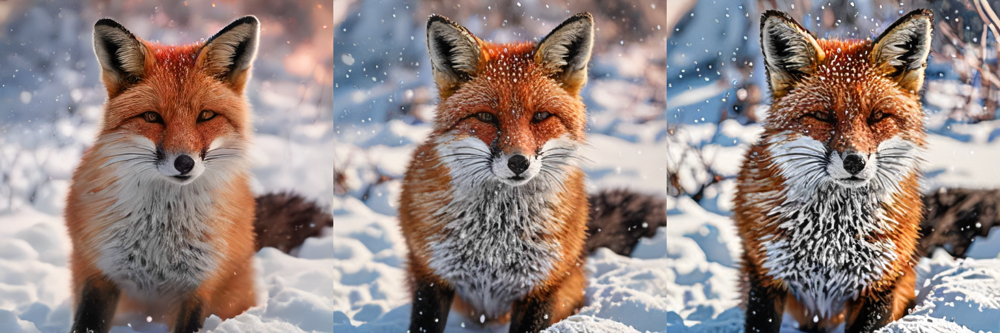

In [9]:
sweep = {}
for steps in (1, 2, 4):
    with bench.track("Task 1", f"sweep:{steps}step", px=CFG.img_px, steps=steps):
        sweep[steps] = generate(PROMPTS["fox"], steps=steps)

for r in bench.rows:
    if r["phase"].startswith("sweep"):
        print(f"{r['steps']} step(s): {r['seconds']:6.2f}s")

grid = make_image_grid(list(sweep.values()), rows=1, cols=len(sweep))
grid.save(art.put("t1_step_sweep", OUT / "t1_step_sweep.png"))
grid

In [10]:
pipes.evict("txt2img")
print("unloaded |", ram())

unloaded | RAM 9.4/51 GB


---
## Task 2 — Image to Video: `ByteDance/AnimateDiff-Lightning`

AnimateDiff inserts temporal self-attention layers between the spatial layers of a frozen SD 1.5 UNet. The motion module trains on video while the image model stays untouched, so any SD 1.5 checkpoint becomes a video model by plugging the adapter in. ByteDance then distilled that module to a 4-step schedule; original AnimateDiff needs ~25 steps with CFG, which is 50 UNet passes per frame.

**Image conditioning.** AnimateDiff is natively text-to-video. To drive it from a still, `AnimateDiffVideoToVideoPipeline` takes the image repeated N times as the input clip with `strength < 1.0`. It noises that clip partway and denoises from there, so composition and subject survive while temporal attention adds motion. Set `strength=1.0` and the input stops mattering, which is how you demonstrate the conditioning is real.

**Resolution is not a free knob.** SD 1.5 and the motion module were both trained at 512×512. At 256 the latent is 32×32 and the model collapses into incoherent blotches. This is the single most common way to get a bad result here, and it is why the preset floor is 384.

Effective steps are `vid_steps × vid_strength`, so `4 × 0.75 = 3` taken from a 4-step schedule, matching the adapter.

In [11]:
from diffusers import (AnimateDiffVideoToVideoPipeline, MotionAdapter,
                       EulerDiscreteScheduler)
from diffusers.utils import export_to_video, export_to_gif, load_image
from huggingface_hub import hf_hub_download
from safetensors.torch import load_file

def load_img2vid():
    adapter = MotionAdapter().to(DEVICE, DTYPE)
    adapter.load_state_dict(load_file(hf_hub_download(MODELS["motion"], MOTION_CKPT),
                                      device="cpu"))
    pipe = build(AnimateDiffVideoToVideoPipeline, MODELS["base"],
                 motion_adapter=adapter, vae=tiny_vae())
    # Lightning was distilled against this exact scheduler configuration.
    pipe.scheduler = EulerDiscreteScheduler.from_config(
        pipe.scheduler.config, timestep_spacing="trailing", beta_schedule="linear")
    return pipe

with bench.track("Task 2", "load", model=MODELS["motion"]):
    img2vid = pipes.get("img2vid", load_img2vid)

print(ram(), "|", disk())

There are modules in MotionAdapter that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


animatediff_lightning_4step_diffusers.sa(…): reconstructing file:   0%|          |  0.00B /  908MB            

animatediff_lightning_4step_diffusers.sa(…): downloading bytes:           |  0.00B            

model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

Expected types for vae: (<class 'diffusers.models.autoencoders.autoencoder_kl.AutoencoderKL'>,), got <class 'diffusers.models.autoencoders.autoencoder_tiny.AutoencoderTiny'>.
There are modules in UNetMotionModel that should be kept in float32: []. Casting directly with `to()` can lead to inconsistent results; set `torch_dtype` in `from_pretrained()` instead to keep these modules in float32.


  Task 2 · load: 49.18s
RAM 18.0/51 GB | disk 26/242 GB


measured 5.0s per unit in Task 1 -> ETA 11-18 min for 8 frames at 512px



  0%|          | 0/3 [00:00<?, ?it/s]

  Task 2 · animate: 287.44s
8 frames at 512px | RAM 18.1/51 GB


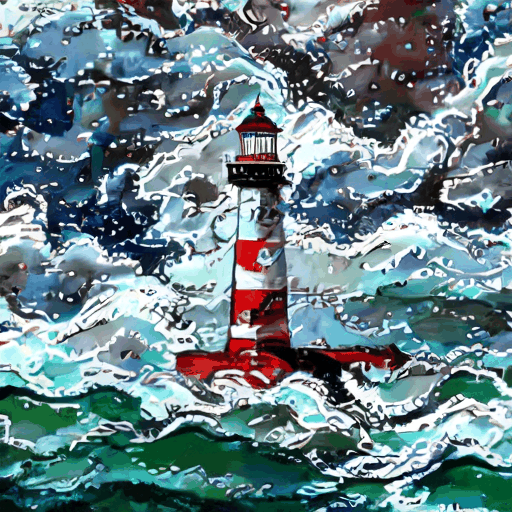

In [12]:
def animate(still, prompt, px=None, frames=None, steps=None, strength=None, seed=42):
    px       = px or CFG.vid_px
    frames   = frames or CFG.vid_frames
    steps    = steps or CFG.vid_steps
    strength = CFG.vid_strength if strength is None else strength
    still = still.convert("RGB").resize((px, px))
    return img2vid(video=[still] * frames, prompt=prompt,
                   num_inference_steps=steps, strength=strength,
                   guidance_scale=1.0,                       # Lightning: distilled without CFG
                   generator=torch.Generator("cpu").manual_seed(seed)).frames[0]

seed_img = load_image(art["t1_lighthouse"])                  # linked to Task 1's output
MOTION_PROMPT = ("a lighthouse in a storm, waves crashing against the rocks, "
                 "clouds drifting across the sky, cinematic")

# Extrapolate from Task 1 rather than guessing. Cost scales with frames x effective
# steps x pixel area; the motion modules add roughly 40% on top of a plain SD UNet.
t1 = [r["seconds"] for r in bench.rows if r["phase"].startswith("generate")]
unit = (sum(t1) / len(t1)) / (CFG.img_px / 256) ** 2 / CFG.img_steps
work = CFG.vid_frames * CFG.vid_steps * CFG.vid_strength * (CFG.vid_px / 256) ** 2
eta = unit * work * 1.4
print(f"measured {unit:.1f}s per unit in Task 1 -> ETA {eta/60:.0f}-{eta*1.6/60:.0f} min "
      f"for {CFG.vid_frames} frames at {CFG.vid_px}px\n")

with bench.track("Task 2", "animate", px=CFG.vid_px, frames=CFG.vid_frames,
                 steps=CFG.vid_steps, strength=CFG.vid_strength):
    frames = animate(seed_img, MOTION_PROMPT)

export_to_video(frames, art.put("t2_video", OUT / "t2_clip.mp4"), fps=8)
export_to_gif(frames, art.put("t2_gif", OUT / "t2_clip.gif"))

from IPython.display import Image as GIF, display
print(f"{len(frames)} frames at {CFG.vid_px}px |", ram())
display(GIF(filename=art["t2_gif"]))

The strip below is better evidence than the clip itself: input on the left, generated frames to the right. It shows the output inherits the still rather than being generated from the prompt alone.

left = input still · right = generated frames


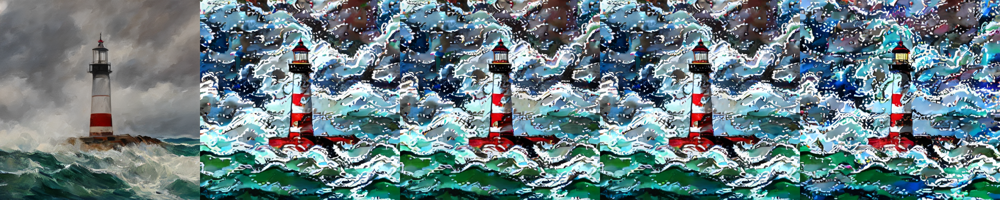

In [13]:
picks = frames[:: max(1, len(frames) // 4)][:4]
strip = make_image_grid([seed_img.resize(picks[0].size)] + picks, rows=1, cols=len(picks) + 1)
strip.save(art.put("t2_strip", OUT / "t2_conditioning_strip.png"))
print("left = input still · right = generated frames")
strip

In [14]:
pipes.evict("img2vid")
print("unloaded |", ram(), "|", disk())

unloaded | RAM 18.1/51 GB | disk 26/242 GB


---
## Task 3 — Text Classification: `SamLowe/roberta-base-go_emotions`

A `roberta-base` encoder (125M, 12 layers) fine-tuned on GoEmotions: 58k Reddit comments labelled across 27 emotions plus `neutral`.

It is **multi-label**, not multi-class. The head applies an independent sigmoid per logit instead of a softmax across them, so scores do not sum to 1 and a sentence can be *admiration* and *pride* and *excitement* at once. Hence `top_k=None`, and hence a decision threshold rather than an argmax.

One forward pass, no iterative denoising. The contrast with the two diffusion models is the point of the timing discussion.

In [15]:
from transformers import pipeline as hf_pipeline

def load_emotion():
    return hf_pipeline("text-classification", model=MODELS["emotion"],
                       top_k=None, device=0 if DEVICE == "cuda" else -1)

with bench.track("Task 3", "load", model=MODELS["emotion"]):
    emotion = pipes.get("emotion", load_emotion, heavy=False)   # 125M, stays resident

print("labels:", len(emotion.model.config.id2label), "|", ram())

config.json:   0%|          | 0.00/1.92k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/380 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.11M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/280 [00:00<?, ?B/s]

  Task 3 · load: 7.64s
labels: 28 | RAM 18.2/51 GB


In [16]:
SAMPLES = [
    "I cannot believe we finally shipped this. I am so proud of the whole team.",
    "The flight was delayed four hours and nobody bothered to tell us anything.",
    "Hmm, I am not sure that is how the loss function is supposed to behave.",
    "Thank you so much, this genuinely made my week.",
    "I am dreading the exam on Friday and I have barely started revising.",
]

emotion("warm up")

def classify(text):
    return {d["label"]: d["score"] for d in emotion(text)[0]}

rows = []
for i, text in enumerate(SAMPLES, 1):
    with bench.track("Task 3", f"classify:{i}", chars=len(text)):
        scores = classify(text)
    top = sorted(scores.items(), key=lambda kv: -kv[1])[:3]
    rows.append({"text": text[:46] + "...",
                 **{f"top{n}": f"{l} ({s:.3f})" for n, (l, s) in enumerate(top, 1)}})

results_t3 = pd.DataFrame(rows)
results_t3.to_csv(art.put("t3_results", OUT / "t3_results.csv"), index=False)
results_t3

  Task 3 · classify:1: 0.30s
  Task 3 · classify:2: 0.39s
  Task 3 · classify:3: 0.21s
  Task 3 · classify:4: 0.30s
  Task 3 · classify:5: 0.30s


,text,top1,top2,top3
0,I cannot believe we finally shipped this. I am...,admiration (0.343),pride (0.310),excitement (0.110)
1,The flight was delayed four hours and nobody b...,disappointment (0.499),neutral (0.289),annoyance (0.262)
2,"Hmm, I am not sure that is how the loss functi...",confusion (0.909),neutral (0.092),approval (0.037)
3,"Thank you so much, this genuinely made my week...",gratitude (0.991),approval (0.014),joy (0.014)
4,I am dreading the exam on Friday and I have ba...,fear (0.228),nervousness (0.128),disappointment (0.120)


**Batching.** A `transformers` pipeline does not batch a list unless you pass `batch_size`. Without it you get a Python loop with per-call overhead, which can read *slower* than single-sentence timing. The two numbers below make that explicit.

In [17]:
with bench.track("Task 3", "sequential:5"):
    [classify(t) for t in SAMPLES]

batched = hf_pipeline("text-classification", model=MODELS["emotion"],
                      top_k=None, batch_size=len(SAMPLES),
                      device=0 if DEVICE == "cuda" else -1)
batched("warm up")
with bench.track("Task 3", "batched:5", batch_size=len(SAMPLES)):
    batched(SAMPLES)

seq = next(r["seconds"] for r in bench.rows if r["phase"] == "sequential:5")
bat = next(r["seconds"] for r in bench.rows if r["phase"] == "batched:5")
print(f"\n{seq / 5 * 1000:.0f} ms/sentence sequential · {bat / 5 * 1000:.0f} ms batched "
      f"({seq / bat:.2f}x)")
del batched; gc.collect()

  Task 3 · sequential:5: 1.59s


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

  Task 3 · batched:5: 0.50s

318 ms/sentence sequential · 101 ms batched (3.16x)


0

**Threshold behaviour.** Independent sigmoids mean the label set grows as the threshold drops. Sweeping it shows the precision/recall trade a deployment would have to pick.

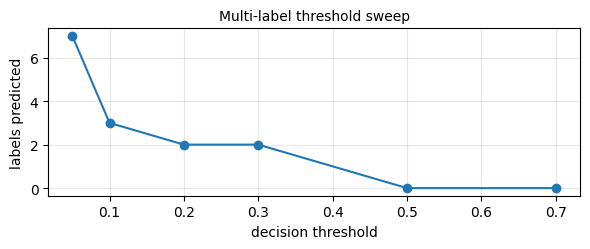

{'admiration': 0.343, 'pride': 0.31, 'excitement': 0.11, 'surprise': 0.096, 'joy': 0.088}


In [18]:
import matplotlib.pyplot as plt

scores = classify(SAMPLES[0])
ths = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7]
counts = [sum(v >= t for v in scores.values()) for t in ths]

fig, ax = plt.subplots(figsize=(6, 2.6))
ax.plot(ths, counts, "o-")
ax.set_xlabel("decision threshold"); ax.set_ylabel("labels predicted")
ax.set_title("Multi-label threshold sweep", fontsize=10)
ax.grid(alpha=.3); fig.tight_layout()
fig.savefig(art.put("t3_threshold", OUT / "t3_threshold.png"), dpi=140)
plt.show()

print({k: round(v, 3) for k, v in sorted(scores.items(), key=lambda kv: -kv[1])[:5]})

---
## 5. Results

The bench log carries the settings alongside each duration, so the table below is self-describing. A number without its hardware is not a measurement.

In [19]:
results = bench.frame()
results["minutes"] = (results["seconds"] / 60).round(2)
results.to_csv(art.put("timings", OUT / "timings.csv"), index=False)

print(f"host      {HOST}")
print(f"precision {DTYPE_WHY}")
print(f"preset    {CFG.label}")
print(f"total     {bench.total() / 60:.1f} min\n")
results

host      CPU x24 threads, 51 GB RAM
precision fp32 (bf16 only 0.00x, not worth it)
preset    report
total     9.0 min



,task,phase,seconds,model,px,steps,frames,strength,chars,batch_size,minutes
0,Task 1,load,29.192,stabilityai/sd-turbo,NaN,NaN,NaN,NaN,NaN,NaN,0.49
1,Task 1,generate:fox,20.997,NaN,512.0,1.0,NaN,NaN,NaN,NaN,0.35
2,Task 1,generate:lighthouse,17.005,NaN,512.0,1.0,NaN,NaN,NaN,NaN,0.28
3,Task 1,generate:cafe,22.206,NaN,512.0,1.0,NaN,NaN,NaN,NaN,0.37
4,Task 1,sweep:1step,18.001,NaN,512.0,1.0,NaN,NaN,NaN,NaN,0.30
5,Task 1,sweep:2step,33.101,NaN,512.0,2.0,NaN,NaN,NaN,NaN,0.55
6,Task 1,sweep:4step,52.798,NaN,512.0,4.0,NaN,NaN,NaN,NaN,0.88
7,Task 2,load,49.178,ByteDance/AnimateDiff-Lightning,NaN,NaN,NaN,NaN,NaN,NaN,0.82
8,Task 2,animate,287.438,NaN,512.0,4.0,8.0,0.75,NaN,NaN,4.79
9,Task 3,load,7.635,SamLowe/roberta-base-go_emotions,NaN,NaN,NaN,NaN,NaN,NaN,0.13


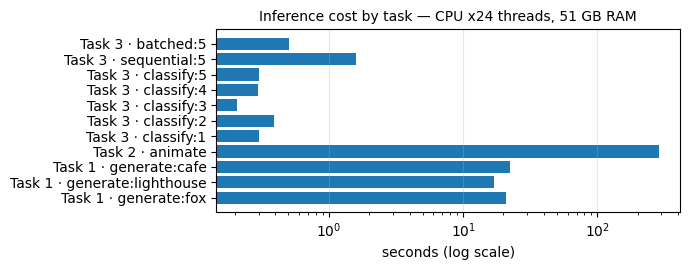

In [20]:
summary = results.groupby("task")["seconds"].agg(["sum", "count"]).reset_index()

fig, ax = plt.subplots(figsize=(7, 2.8))
infer = results[~results["phase"].str.startswith(("load", "sweep"))]
ax.barh(infer["task"] + " · " + infer["phase"], infer["seconds"])
ax.set_xscale("log"); ax.set_xlabel("seconds (log scale)")
ax.set_title(f"Inference cost by task — {HOST}", fontsize=10)
ax.grid(axis="x", alpha=.3); fig.tight_layout()
fig.savefig(art.put("timing_chart", OUT / "timings.png"), dpi=140)
plt.show()

### Generated report stub

Writes `outputs/RESULTS.md` with the audit table, timings and artifact list already filled in. Commit it, or paste the sections into the report.

In [21]:
report = f"""# Results

**Host** {HOST}
**Precision** {DTYPE_WHY}
**Preset** `{CFG.label}` — {asdict(CFG)}
**Torch** {torch.__version__} · **Python** {platform.python_version()}
**Total runtime** {bench.total() / 60:.1f} min

## Model audit

{audit_df.to_markdown(index=False)}

## Timings

{results.to_markdown(index=False)}

## Classification output

{results_t3.to_markdown(index=False)}

## Artifacts

{chr(10).join(f'- `{k}` → `{v}`' for k, v in art.items())}
"""

(OUT / "RESULTS.md").write_text(report)
art.put("results_md", OUT / "RESULTS.md")
art.save_manifest()
print(report[:700], "...")

# Results

**Host** CPU x24 threads, 51 GB RAM
**Precision** fp32 (bf16 only 0.00x, not worth it)
**Preset** `report` — {'label': 'report', 'img_px': 512, 'img_steps': 1, 'vid_px': 512, 'vid_frames': 8, 'vid_steps': 4, 'vid_strength': 0.75}
**Torch** 2.14.1+cpu · **Python** 3.13.16
**Total runtime** 9.0 min

## Model audit

| repo                                        | gated   | license               | task                |   downloads |   likes |
|:--------------------------------------------|:--------|:----------------------|:--------------------|------------:|--------:|
| stabilityai/sd-turbo                        | False   | see card              | text-to-image       |     752,313 |  ...


### Reclaiming disk

Hub weights persist after the pipelines are unloaded. Useful when a runtime is short on disk; skip it if you are about to launch Gradio, which reloads from cache.

In [22]:
from huggingface_hub import scan_cache_dir

def cache_table():
    c = scan_cache_dir()
    rows = [{"repo": r.repo_id, "GB": round(r.size_on_disk / 1e9, 2)} for r in c.repos]
    return pd.DataFrame(rows).sort_values("GB", ascending=False), c

def purge(keep=()):
    df, c = cache_table()
    doomed = [r for r in c.repos if r.repo_id not in keep]
    strategy = c.delete_revisions(*[rev.commit_hash for r in doomed for rev in r.revisions])
    print(f"freeing {strategy.expected_freed_size_str}")
    strategy.execute()

tbl, _ = cache_table()
print(f"{tbl['GB'].sum():.1f} GB cached |", disk())
tbl

6.4 GB cached | disk 27/242 GB


,repo,GB
4,stable-diffusion-v1-5/stable-diffusion-v1-5,2.57
0,stabilityai/sd-turbo,2.41
3,ByteDance/AnimateDiff-Lightning,0.91
1,SamLowe/roberta-base-go_emotions,0.50
2,madebyollin/taesd,0.01


---
## 6. Gradio

Three tabs over the same `pipes` cache and `art` registry used above, so there is no second copy of the loading logic. Tab 1 pipes its output straight into Tab 2.

Only one diffusion pipeline stays resident, so the first click on a tab pays a load and later clicks do not. Keep Tab 2's sliders low unless you intend to wait.

In [23]:
import gradio as gr

def ui_txt2img(prompt, px, steps, seed, progress=gr.Progress()):
    if not prompt.strip():
        return None, "Enter a prompt."
    progress(0, desc="loading SD-Turbo")
    global txt2img
    txt2img = pipes.get("txt2img", load_txt2img)
    px = int(px) - int(px) % 8
    progress(.3, desc="denoising")
    t0 = time.perf_counter()
    img = generate(prompt, px=px, steps=int(steps), seed=int(seed))
    return img, f"**{time.perf_counter() - t0:.2f}s** · {int(steps)} step · {px}px · {HOST}"


def ui_img2vid(image, prompt, px, frames, steps, strength, progress=gr.Progress()):
    if image is None:
        return None, "Upload an image, or generate one in Tab 1 and press *Send →*."
    progress(0, desc="loading AnimateDiff-Lightning")
    global img2vid
    img2vid = pipes.get("img2vid", load_img2vid)
    px = int(px) - int(px) % 8
    progress(.3, desc=f"{int(frames)} frames, a few minutes on CPU")
    t0 = time.perf_counter()
    out = animate(image, prompt, px=px, frames=int(frames),
                  steps=int(steps), strength=float(strength))
    dt = time.perf_counter() - t0
    path = OUT / f"ui_clip_{int(time.time())}.mp4"
    export_to_video(out, str(path), fps=8)
    eff = max(1, round(int(steps) * float(strength)))
    return str(path), (f"**{dt:.0f}s** ({dt/60:.1f} min) · {int(frames)} frames · "
                       f"{px}px · ~{eff} effective steps · {HOST}")


def ui_classify(text, threshold):
    if not text.strip():
        return {}, "Enter some text."
    t0 = time.perf_counter()
    scores = classify(text)
    dt = time.perf_counter() - t0
    hits = [k for k, v in scores.items() if v >= threshold] or ["none above threshold"]
    return scores, f"**{dt * 1000:.0f} ms** · ≥{threshold:.2f}: {', '.join(hits)}"

print("handlers ready")

handlers ready


In [25]:
with gr.Blocks(title="Three models on a CPU budget", theme=gr.themes.Soft()) as demo:
    gr.Markdown(f"# Three Hugging Face models on a CPU budget\n"
                f"Running on **{HOST}** · {DTYPE_WHY}. First click per tab includes the model load.")

    with gr.Tab("1 · Text to Image"):
        gr.Markdown("`stabilityai/sd-turbo` — one-step distilled Stable Diffusion 2.1")
        with gr.Row():
            with gr.Column():
                a_prompt = gr.Textbox(label="Prompt", lines=3, value=PROMPTS["fox"])
                a_px     = gr.Slider(256, 512, value=CFG.img_px, step=64, label="Resolution")
                a_steps  = gr.Slider(1, 4, value=1, step=1, label="Steps")
                a_seed   = gr.Number(value=42, label="Seed", precision=0)
                a_go     = gr.Button("Generate", variant="primary")
                gr.Markdown("*Guidance is pinned to 0.0 — Turbo was distilled without CFG.*")
            with gr.Column():
                a_out  = gr.Image(label="Output", type="pil", height=360)
                a_time = gr.Markdown()
                a_send = gr.Button("Send to Tab 2 →")

    with gr.Tab("2 · Image to Video"):
        gr.Markdown("`ByteDance/AnimateDiff-Lightning` on SD 1.5 — 4-step motion adapter")
        with gr.Row():
            with gr.Column():
                b_img      = gr.Image(label="Conditioning image", type="pil", height=200)
                b_prompt   = gr.Textbox(label="Motion prompt", lines=2, value=MOTION_PROMPT)
                b_px       = gr.Slider(384, 512, value=CFG.vid_px, step=64, label="Resolution")
                b_frames   = gr.Slider(6, 16, value=CFG.vid_frames, step=2, label="Frames")
                b_steps    = gr.Slider(4, 8, value=CFG.vid_steps, step=1, label="Steps")
                b_strength = gr.Slider(.3, .9, value=CFG.vid_strength, step=.05,
                                       label="Strength (low = closer to your image)")
                b_go = gr.Button("Animate", variant="primary")
                gr.Markdown("*Below 384px SD 1.5 degrades sharply. Loading this evicts Tab 1.*")
            with gr.Column():
                b_out  = gr.Video(label="Output", height=360)
                b_time = gr.Markdown()

    with gr.Tab("3 · Text Classification"):
        gr.Markdown("`SamLowe/roberta-base-go_emotions` — 28 independent sigmoids")
        with gr.Row():
            with gr.Column():
                c_text = gr.Textbox(label="Text", lines=5, value=SAMPLES[0])
                c_thr  = gr.Slider(.05, .9, value=.3, step=.05, label="Decision threshold")
                c_go   = gr.Button("Classify", variant="primary")
                gr.Examples([[s, .3] for s in SAMPLES[1:]], inputs=[c_text, c_thr])
            with gr.Column():
                c_out  = gr.Label(label="Scores (not a softmax — these do not sum to 1)",
                                  num_top_classes=6)
                c_time = gr.Markdown()

    a_go.click(ui_txt2img, [a_prompt, a_px, a_steps, a_seed], [a_out, a_time])
    a_send.click(lambda im: im, a_out, b_img)
    b_go.click(ui_img2vid, [b_img, b_prompt, b_px, b_frames, b_steps, b_strength],
               [b_out, b_time])
    c_go.click(ui_classify, [c_text, c_thr], [c_out, c_time])

demo.queue().launch(share=True)        # returns immediately, renders inline

/tmp/ipykernel_126570/4220043426.py:1: UserWarning: The parameters have been moved from the Blocks constructor to the launch() method in Gradio 6.0: theme. Please pass these parameters to launch() instead.
  with gr.Blocks(title="Three models on a CPU budget", theme=gr.themes.Soft()) as demo:


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://dba5b3683cca878440.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
## 7. Submission checklist

Everything in `outputs/` is already written and listed in `manifest.json`.

**Per task:** model card page with no gating banner · the "Use this model" snippet panel · the code cell · the output · the timing row with the host named.

**Plus:** the Gradio tabs with results rendered (not empty forms), the audit table from section 3, and the step-scaling figure.

**To push:**

```bash
git init && git add . && git commit -m "Three HF models on a CPU budget"
git remote add origin git@github.com:USER/cpu-diffusion-toolkit.git
git push -u origin main
```

Add `outputs/ui_clip_*.mp4` to `.gitignore` if the interactive clips pile up.

## Troubleshooting

| Symptom | Cause |
|---|---|
| `NameError` on `CFG`, `bench`, `art` | A cell above was skipped. `Runtime → Run all`. |
| Session crashed, out of RAM | Two pipelines resident. The cache keeps one; do not skip the `pipes.evict` cells. |
| Video is incoherent blotches | Resolution below 384. Raise `vid_px`. |
| Video ignores the input image | `strength` too high. Drop toward 0.5. |
| A cell looks frozen | A single CPU denoising step can take 30s+. Watch the Colab RAM gauge. |